# Async vs Sync in Python

This notebook compares **synchronous** execution (one task after another) with **asynchronous** execution (`asyncio`, several tasks interleaved on a single thread) using measurable examples.

**Contents**
1. The idea in one sentence
2. I/O tasks: sync vs async
3. How does it scale with more tasks?
4. Comparison with threads (`ThreadPoolExecutor`)
5. Where async does **not** help: CPU-bound tasks
6. The classic mistake: blocking the event loop
7. Limiting concurrency with `Semaphore`
8. Real-world example
9. Summary: when to use each

> **Note:** Jupyter already has an event loop running, so here we use `await` directly in the cell. In a regular `.py` script you would use `asyncio.run(main())`.

> So the notebook works without internet, I/O (an HTTP request, a database query) is simulated with `time.sleep` / `asyncio.sleep`. The behavior is the same: the program *waits* without using the CPU.

## 1. The idea in one sentence

- **Sync:** while one task waits (network, disk, database), the whole program waits with it.
- **Async:** while one task waits, the *event loop* hands control to another task that can make progress.

Async **does not make code faster**: it makes the *waiting* overlap. That's why it shines with I/O and is useless for pure computation.

### Import libraries

In [1]:
import asyncio
import time
import math
from concurrent.futures import ThreadPoolExecutor, ProcessPoolExecutor

import matplotlib.pyplot as plt

def timer(func):
    """Run func() and return (result, seconds)."""
    t0 = time.perf_counter()
    res = func()
    return res, time.perf_counter() - t0

async def timer_async(coro):
    """Await coro and return (result, seconds)."""
    t0 = time.perf_counter()
    res = await coro
    return res, time.perf_counter() - t0

## 2. I/O tasks: sync vs async

We simulate 10 "requests" that take 0.5 s each.

### Synchronous version

In [2]:
N_TASKS = 10
LATENCY = 0.5

def request_sync(i):
    time.sleep(LATENCY)
    return f"response {i}"

def main_sync():
    return [request_sync(i) for i in range(N_TASKS)]

_, t_sync = timer(main_sync)
print(f"Sync : {t_sync:.2f} s")

Sync : 5.03 s


### Asynchronous version

In [3]:
async def request_async(i):
    await asyncio.sleep(LATENCY)
    return f"response {i}"

async def main_async():
    return await asyncio.gather(*(request_async(i) for i in range(N_TASKS)))

_, t_async = await timer_async(main_async())
print(f"Async: {t_async:.2f} s")
print(f"Speedup: {t_sync / t_async:.1f}x")

Async: 0.50 s
Speedup: 10.1x


The sync time is ≈ `N_TASKS × LATENCY`; the async time is ≈ `LATENCY`, because all the waiting happens at the same time.

### Visualizing the timeline

We record when each task starts and ends to see the difference.

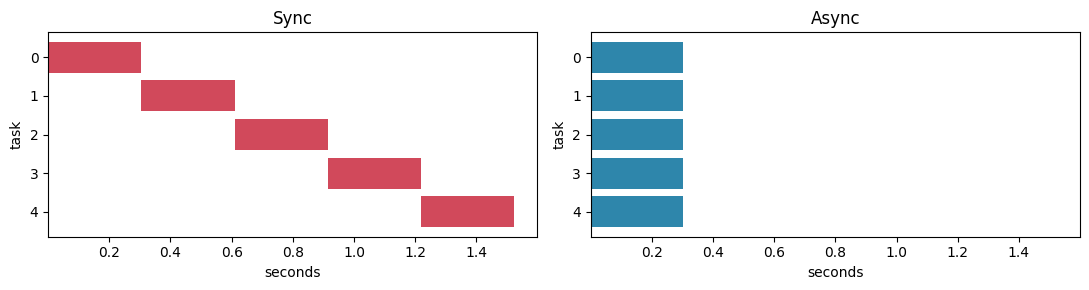

In [4]:
def timeline_sync(n=5, lat=0.3):
    t0 = time.perf_counter(); marks = []
    for i in range(n):
        start = time.perf_counter() - t0
        time.sleep(lat)
        marks.append((i, start, time.perf_counter() - t0))
    return marks

async def timeline_async(n=5, lat=0.3):
    t0 = time.perf_counter(); marks = []
    async def task(i):
        start = time.perf_counter() - t0
        await asyncio.sleep(lat)
        marks.append((i, start, time.perf_counter() - t0))
    await asyncio.gather(*(task(i) for i in range(n)))
    return sorted(marks)

m_sync = timeline_sync()
m_async = await timeline_async()

fig, axes = plt.subplots(1, 2, figsize=(11, 3), sharex=True)
for ax, marks, title, color in [(axes[0], m_sync, "Sync", "#d1495b"),
                                (axes[1], m_async, "Async", "#2e86ab")]:
    for i, start, end in marks:
        ax.barh(i, end - start, left=start, color=color)
    ax.set_title(title); ax.set_xlabel("seconds"); ax.set_ylabel("task")
    ax.invert_yaxis()
plt.tight_layout(); plt.show()

## 3. How does it scale with more tasks?

Sync grows linearly; async stays almost flat (as long as the bottleneck is the waiting).

n=  1  sync=  0.10s  async= 0.10s
n=  5  sync=  0.52s  async= 0.10s
n= 10  sync=  1.04s  async= 0.10s
n= 25  sync=  2.59s  async= 0.10s
n= 50  sync=  5.17s  async= 0.10s
n=100  sync= 10.35s  async= 0.10s


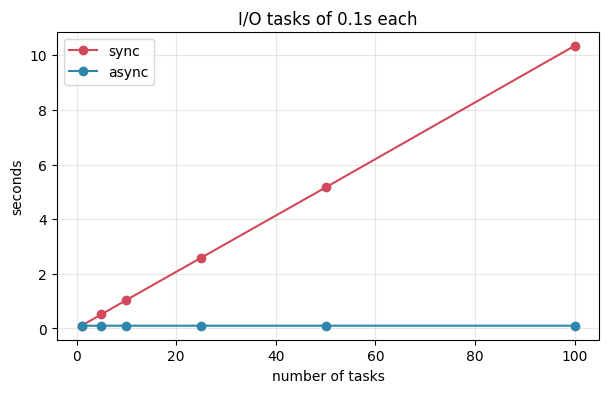

In [5]:
LAT = 0.1
sizes = [1, 5, 10, 25, 50, 100]
times_sync, times_async = [], []

for n in sizes:
    _, ts = timer(lambda: [time.sleep(LAT) for _ in range(n)])
    _, ta = await timer_async(asyncio.gather(*(asyncio.sleep(LAT) for _ in range(n))))
    times_sync.append(ts); times_async.append(ta)
    print(f"n={n:>3}  sync={ts:6.2f}s  async={ta:5.2f}s")

plt.figure(figsize=(7, 4))
plt.plot(sizes, times_sync, "o-", label="sync", color="#d1495b")
plt.plot(sizes, times_async, "o-", label="async", color="#2e86ab")
plt.xlabel("number of tasks"); plt.ylabel("seconds")
plt.title(f"I/O tasks of {LAT}s each"); plt.legend(); plt.grid(alpha=.3)
plt.show()

## 4. What about threads?

Threads (`threading` / `ThreadPoolExecutor`) also overlap I/O waits, because the GIL is released during `sleep`, network reads, etc. So why async?

- **Threads:** work with existing synchronous libraries (`requests`, classic DB drivers). Each thread uses memory (~MB of stack) and the OS switches between them preemptively → possible race conditions.
- **Async:** thousands of tasks cost very little (each one is a small object); task switches only happen at `await` points, which makes the code more predictable. Requires async libraries (`httpx`, `aiohttp`, `asyncpg`…).

sync (estimated)   40.67 s
threads (10)        4.08 s
threads (200)       0.22 s
async               0.20 s


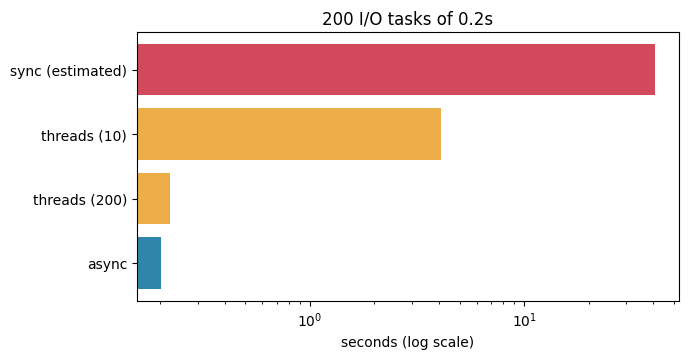

In [6]:
N = 200
LAT = 0.2

_, t_s = timer(lambda: [time.sleep(LAT) for _ in range(N // 10)])
t_s *= 10

def with_threads(workers):
    with ThreadPoolExecutor(max_workers=workers) as ex:
        list(ex.map(lambda _: time.sleep(LAT), range(N)))

_, t_t10 = timer(lambda: with_threads(10))
_, t_t200 = timer(lambda: with_threads(200))
_, t_a = await timer_async(asyncio.gather(*(asyncio.sleep(LAT) for _ in range(N))))

results = {"sync (estimated)": t_s, "threads (10)": t_t10, "threads (200)": t_t200, "async": t_a}
for k, v in results.items():
    print(f"{k:<17} {v:6.2f} s")

plt.figure(figsize=(7, 3.5))
plt.barh(list(results), list(results.values()),
         color=["#d1495b", "#edae49", "#edae49", "#2e86ab"])
plt.xscale("log"); plt.xlabel("seconds (log scale)")
plt.title(f"{N} I/O tasks of {LAT}s"); plt.gca().invert_yaxis()
plt.show()

With enough threads, the result is similar to async. The difference shows up with **thousands or tens of thousands** of simultaneous connections: creating 10,000 threads is expensive; creating 10,000 coroutines is not.

### Memory Comparison

In [7]:
import tracemalloc

async def measure_memory_async(n):
    tracemalloc.start()
    tasks = [asyncio.create_task(asyncio.sleep(0.5)) for _ in range(n)]
    current, _ = tracemalloc.get_traced_memory()
    await asyncio.gather(*tasks)
    tracemalloc.stop()
    return current

n = 10_000
mem = await measure_memory_async(n)
print(f"{n:,} async tasks ≈ {mem / 1024 / 1024:.1f} MB in Python objects "
      f"(~{mem / n / 1024:.2f} KB per task)")
print("For reference: each OS thread typically reserves ~8 MB of virtual stack on Linux.")

10,000 async tasks ≈ 11.3 MB in Python objects (~1.16 KB per task)
For reference: each OS thread typically reserves ~8 MB of virtual stack on Linux.


## 5. Where async does **not** help: CPU-bound tasks

If the task computes instead of waiting, there is never a moment to yield control. Async ends up the same as sync (or slightly worse due to overhead). For CPU work, what helps is **real parallelism with processes** (`ProcessPoolExecutor` / `multiprocessing`), which sidesteps the GIL.

In [8]:
import os; print(os.getcwd())

/Users/alberto_valdes/Desktop/lab


In [9]:
from utils import cpu_work   # imported from a module so worker processes can find it

N_CPU = 4

_, t_cpu_sync = timer(lambda: [cpu_work() for _ in range(N_CPU)])

async def cpu_async():
    async def task():
        return cpu_work()   # there is no useful await inside
    return await asyncio.gather(*(task() for _ in range(N_CPU)))

_, t_cpu_async = await timer_async(cpu_async())

def with_processes():
    with ProcessPoolExecutor(max_workers=N_CPU) as ex:
        return list(ex.map(cpu_work, [2_000_000] * N_CPU))

_, t_cpu_proc = timer(with_processes)

print(f"Sync      : {t_cpu_sync:.2f} s")
print(f"Async     : {t_cpu_async:.2f} s   <- no improvement")
print(f"Processes : {t_cpu_proc:.2f} s   (depends on how many cores you have)")

Sync      : 0.27 s
Async     : 0.24 s   <- no improvement
Processes : 0.12 s   (depends on how many cores you have)


> **Note on processes in notebooks:** on Linux, functions defined in the notebook work directly with `ProcessPoolExecutor`. On macOS and Windows, worker processes start from scratch and can't see functions defined in the notebook, so `cpu_work` lives in a separate `utils.py` file and is imported from there.
>
> Python 3.13+ also has an experimental "free-threaded" build (no GIL) where threads can actually parallelize CPU work.

## 6. The classic mistake: blocking the event loop

If inside a coroutine you call something **synchronous and slow** (`time.sleep`, `requests.get`, a query with a sync driver), you block the entire event loop: no other task makes progress. You lose all the benefit of async without any warning.

In [10]:
async def bad(i):
    time.sleep(0.3)
    return i

async def good(i):
    await asyncio.sleep(0.3)
    return i

async def wrapped(i):
    await asyncio.to_thread(time.sleep, 0.3)
    return i

for f in (bad, good, wrapped):
    _, t = await timer_async(asyncio.gather(*(f(i) for i in range(10))))
    print(f"{f.__name__:<8} {t:.2f} s")

bad      3.04 s
good     0.30 s
wrapped  0.31 s


If `wrapped` takes a bit longer than `good`, it's because `asyncio.to_thread` uses a thread pool whose default size is `min(32, cores + 4)`: with few cores, the 10 tasks are split into batches.

**Practical rules**
- Inside `async def`, anything that waits on I/O should be `await some_async_call(...)`.
- If there's no async version of a library, use `await asyncio.to_thread(sync_function, ...)`.
- For heavy CPU work inside an async app: `loop.run_in_executor(ProcessPoolExecutor(), ...)`.
- `asyncio.run(main(), debug=True)` warns you when a step of the loop takes too long.

## 7. Limiting concurrency with `Semaphore`

Firing 10,000 requests at once against a real server usually ends in errors or rate-limit blocks. An `asyncio.Semaphore` limits how many tasks run at the same time.

In [11]:
async def limited_request(sem, i, active, peak):
    async with sem:
        active[0] += 1
        peak[0] = max(peak[0], active[0])
        await asyncio.sleep(0.1)
        active[0] -= 1
        return i

for limit in (5, 20, 100):
    sem = asyncio.Semaphore(limit)
    active, peak = [0], [0]
    _, t = await timer_async(
        asyncio.gather(*(limited_request(sem, i, active, peak) for i in range(100))))
    print(f"limit={limit:>3}  time={t:.2f}s  max observed concurrency={peak[0]}")

limit=  5  time=2.03s  max observed concurrency=5
limit= 20  time=0.51s  max observed concurrency=20
limit=100  time=0.10s  max observed concurrency=100


## 8. Real-world example

This is what the comparison looks like with real HTTP requests. You need `pip install requests httpx`. The cell is disabled by default: set `RUN = True`.

In [12]:
RUN = True
URL = "https://httpbin.org/delay/1"   # responds after ~1 s
N_REQ = 10

if RUN:
    import requests, httpx

    _, t = timer(lambda: [requests.get(URL, timeout=10) for _ in range(N_REQ)])
    print(f"requests (sync): {t:.2f} s")

    async def with_httpx():
        async with httpx.AsyncClient(timeout=10) as client:
            return await asyncio.gather(*(client.get(URL) for _ in range(N_REQ)))

    _, t = await timer_async(with_httpx())
    print(f"httpx (async)  : {t:.2f} s")
else:
    print("Cell disabled. Set RUN = True to try it with a real network.")

requests (sync): 15.07 s
httpx (async)  : 1.55 s


## 9. Summary: when to use each

| Type of work | Best option | Why |
|---|---|---|
| Few operations, simple script | **Sync** | Easier to read and debug |
| Lots of concurrent I/O (APIs, scraping, websockets, servers) | **Async** | Thousands of overlapping waits on one thread, low memory |
| Concurrent I/O with sync-only libraries | **Threads** | Overlap waits without rewriting code |
| Heavy computation (CPU) | **Processes** | Real parallelism, sidesteps the GIL |
| Async app that must call blocking code | `asyncio.to_thread` / `run_in_executor` | Don't block the event loop |

**Key ideas**
1. Async speeds up *waiting*, not *computing*.
2. A single `time.sleep` or slow sync call inside a coroutine ruins concurrency.
3. Async is "contagious": a function that uses `await` must be `async`, and so on up the call chain.
4. Limit concurrency (`Semaphore`) when talking to real services.